# Interpolation and temporal disaggregation

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

Two different problems share the word "interpolation":

1. **Filling gaps** in a series observed at its own frequency (a missing
   month, market holidays).
2. **Temporal disaggregation**: building a monthly series from a quarterly
   one (or quarterly from annual) so that the high-frequency series **adds up**
   to the low-frequency one.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from econts import load

brent = load("DCOILBRENTEU")
ip = load("INDPRO")
gdp = load("GDPC1")

## Filling gaps

In [3]:
s = brent["2024-12-20":"2025-01-03"]
fills = pd.DataFrame(
    {
        "raw": s,
        "ffill": s.ffill(),  # last price carried forward
        "linear": s.interpolate(),  # equal steps per row
        "time": s.interpolate(method="time"),  # steps proportional to time
        "pchip": s.interpolate(method="pchip"),  # shape-preserving cubic
    }
)
print(fills.round(2))

              raw  ffill  linear   time  pchip
date                                          
2024-12-20  73.19  73.19   73.19  73.19  73.19
2024-12-23  72.12  72.12   72.12  72.12  72.12
2024-12-24  73.50  73.50   73.50  73.50  73.50
2024-12-25    NaN  73.50   73.59  73.59  73.63
2024-12-26    NaN  73.50   73.68  73.68  73.69
2024-12-27  73.77  73.77   73.77  73.77  73.77
2024-12-30  74.24  74.24   74.24  74.24  74.24
2024-12-31  74.58  74.58   74.58  74.58  74.58
2025-01-01    NaN  74.58   75.36  75.36  75.31
2025-01-02  76.14  76.14   76.14  76.14  76.14
2025-01-03  76.72  76.72   76.72  76.72  76.72


* `linear` ignores the index, `time` respects uneven spacing. They only
  differ when rows are unevenly spaced in time.
* `pchip` and `akima` are smooth without overshooting; `spline` (order 3) can
  overshoot near sharp moves.
* `limit=2` caps how many consecutive `NaN` are filled; `limit_area="inside"`
  refuses to extrapolate at the ends.

For prices, `ffill` is the market convention (the last traded price is the
price). For flows and smooth economic series, interpolate.

## Gaps filled by a Kalman smoother

A state-space model handles `NaN` natively: the Kalman filter skips the
update step and the smoother fills the gap with the model-consistent path,
along with an uncertainty band. A local linear trend on log IP:

RMSE in the gap: kalman 0.389 | linear 0.364


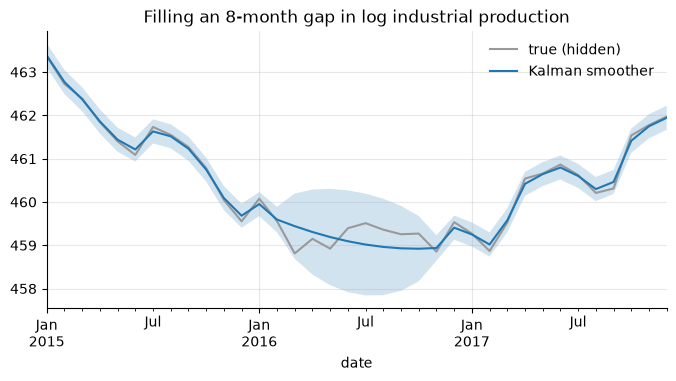

In [4]:
y = 100 * np.log(ip["2010":"2019"]).asfreq("MS")
y_gap = y.copy()
y_gap["2016-03":"2016-10"] = np.nan  # knock out eight months

mod = sm.tsa.UnobservedComponents(y_gap, level="local linear trend")
res = mod.fit(disp=False)
smoothed = pd.Series(res.level.smoothed, index=y.index)
band = 1.96 * np.sqrt(res.level.smoothed_cov)

gap = y_gap.isna()
print(
    "RMSE in the gap: kalman",
    np.sqrt(((smoothed - y)[gap] ** 2).mean()).round(3),
    "| linear",
    np.sqrt(((y_gap.interpolate() - y)[gap] ** 2).mean()).round(3),
)

ax = y["2015":"2017"].plot(color="0.6", label="true (hidden)")
smoothed["2015":"2017"].plot(ax=ax, label="Kalman smoother")
ax.fill_between(
    y["2015":"2017"].index,
    (smoothed - band)["2015":"2017"],
    (smoothed + band)["2015":"2017"],
    alpha=0.2,
)
ax.set_title("Filling an 8-month gap in log industrial production")
ax.legend()

The smoother is no more accurate than a straight line here: a univariate
trend model can only draw a smooth path through the gap. What it adds is the
**uncertainty band**. Accuracy gains come from adding **related series**: a dynamic factor model or a
regression with ARMA errors (`sm.tsa.SARIMAX(y, exog=X)`) uses the other
series' movements during the gap.

## Temporal disaggregation

The target: a monthly series $x$ whose quarterly aggregate equals the
published quarterly series $Y$, i.e. $C x = Y$. For a quarterly average
$C = I_n \otimes [\tfrac13\ \tfrac13\ \tfrac13]$; for a sum, drop the $\tfrac13$.

First, why plain interpolation is wrong:

In [5]:
gdp_q = gdp["2015":"2019"]
naive = gdp_q.resample("MS").interpolate()  # linear through quarter starts
back = naive.resample("QS").mean()
print((back / gdp_q - 1).dropna().abs().max())  # does not add up

0.003900006188636951


### Denton (proportional first difference)

Denton–Cholette keeps the **ratio** of the target to an indicator $i_t$ as
smooth as possible while meeting the constraint:

$$\min_x \sum_t \left(\frac{x_t}{i_t} - \frac{x_{t-1}}{i_{t-1}}\right)^2
\quad \text{s.t.} \quad C x = Y .$$

With a constant indicator, it is a smooth interpolation that adds up. It is
a quadratic program with a closed-form solution:

In [6]:
def agg_matrix(n_low: int, n_high: int, m: int = 3, how: str = "mean") -> np.ndarray:
    """C such that C @ x aggregates consecutive blocks of m high-freq values."""
    C = np.kron(np.eye(n_low), np.ones((1, m)))
    C = np.hstack([C, np.zeros((n_low, n_high - m * n_low))])  # months beyond
    return C / m if how == "mean" else C


def denton(
    Y: pd.Series, indicator: pd.Series, m: int = 3, how: str = "mean"
) -> pd.Series:
    """Proportional Denton benchmarking of `indicator` to the low-frequency `Y`.

    `indicator` must start in the first sub-period of `Y`'s first period. It may
    run past `Y`'s last period; those months are extrapolated with the indicator.
    """
    i = indicator.to_numpy(float)
    T, n = len(i), len(Y)
    C = agg_matrix(n, T, m, how)
    D = np.diff(np.eye(T), axis=0)  # first-difference operator
    A = C * i  # constraint in terms of r = x / i
    K = np.block([[D.T @ D, A.T], [A, np.zeros((n, n))]])
    rhs = np.concatenate([np.zeros(T), Y.to_numpy(float)])
    r = np.linalg.solve(K, rhs)[:T]
    return pd.Series(r * i, index=indicator.index, name=Y.name)


months = pd.date_range("2015-01-01", "2019-12-01", freq="MS")
smooth = denton(gdp_q, pd.Series(1.0, index=months))
print((smooth.resample("QS").mean() / gdp_q - 1).abs().max())  # ~1e-16: adds up

1.5543122344752192e-15


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.disagg import denton
```

With an indicator, monthly GDP inherits the indicator's monthly profile.
When the indicator runs past the last published quarter, Denton also
**extrapolates**. To see how well, hold out the latest quarter (2026Q3)
and benchmark industrial production to GDP up to 2026Q2:

In [7]:
Y = gdp["2010":"2026-04"]  # published GDP up to 2026Q2
target = gdp["2026-07-01"]  # held out: 2026Q3
gdp_m_denton = denton(Y, ip["2010":"2026-09"])
print(gdp_m_denton.tail(6).round(0))  # Jul-Sep 2026 are extrapolated

date
2026-04-01    24411.0
2026-05-01    24392.0
2026-06-01    24421.0
2026-07-01    24478.0
2026-08-01    24494.0
2026-09-01    24656.0
Name: GDPC1, dtype: float64


### Chow–Lin and Fernández (regression-based)

Chow and Lin (1971) assume the monthly target follows a regression on
indicators, $x = X\beta + u$, with AR(1) errors $u_t = \rho u_{t-1} +
\varepsilon_t$. Only $Y = C x$ is observed, so $\beta$ is estimated by GLS
on the aggregated model, $\rho$ by maximum likelihood, and the quarterly
residuals are distributed across months. Fernández (1981) is the limit
$\rho = 1$, random-walk errors, for when target and indicators do not
cointegrate. Both are standard at Eurostat and national statistical offices.

In [8]:
from scipy.optimize import minimize_scalar


def regression_disagg(
    Y: pd.Series,
    X: pd.DataFrame,
    method: str = "chow-lin",
    m: int = 3,
    how: str = "mean",
):
    """Chow-Lin (AR(1) errors) or Fernandez (random-walk errors) disaggregation.

    Returns the high-frequency series and a dict with beta and rho.
    """
    Xh = sm.add_constant(X).to_numpy(float)
    T, n = len(Xh), len(Y)
    C = agg_matrix(n, T, m, how)
    y, Xl = Y.to_numpy(float), C @ Xh
    t = np.arange(T)

    def gls(rho):
        if method == "fernandez":
            S = np.minimum.outer(t, t) + 1.0  # random walk from 0
        else:
            S = rho ** np.abs(np.subtract.outer(t, t)) / (1 - rho**2)
        V = C @ S @ C.T
        Vi = np.linalg.inv(V)
        beta = np.linalg.solve(Xl.T @ Vi @ Xl, Xl.T @ Vi @ y)
        e = y - Xl @ beta
        loglik = -0.5 * (n * np.log(e @ Vi @ e / n) + np.linalg.slogdet(V)[1])
        return beta, e, S, Vi, loglik

    rho = 1.0
    if method == "chow-lin":
        rho = minimize_scalar(
            lambda r: -gls(r)[-1], bounds=(0.0, 0.99), method="bounded"
        ).x
    beta, e, S, Vi, _ = gls(rho)
    x = Xh @ beta + S @ C.T @ Vi @ e  # regression + distributed residual
    return pd.Series(x, index=X.index, name=Y.name), {"beta": beta, "rho": rho}


X = pd.DataFrame({"ip": ip, "payems": load("PAYEMS")})["2010":"2026-09"]
gdp_m_cl, info = regression_disagg(Y, X, "chow-lin")
gdp_m_fe, _ = regression_disagg(Y, X, "fernandez")
print("Chow-Lin rho =", round(info["rho"], 3))
print((gdp_m_fe[: 3 * len(Y)].resample("QS").mean() / Y - 1).abs().max())  # adds up

Chow-Lin rho = 0.99
2.1760371282653068e-14


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.disagg import chow_lin, fernandez
```

The Chow–Lin $\hat\rho$ sits at the upper bound: the regression residual
is close to a random walk, which is the case Fernández is built for. How do
the methods do on the held-out quarter?

In [9]:
nowcast = pd.Series(
    {
        "no change (2026Q2 level)": Y.iloc[-1],
        "Denton, IP": gdp_m_denton["2026-07":].mean(),
        "Chow-Lin, IP + payrolls": gdp_m_cl["2026-07":].mean(),
        "Fernandez, IP + payrolls": gdp_m_fe["2026-07":].mean(),
    }
)
print((100 * (nowcast / target - 1)).round(2).rename("error vs published 2026Q3, %"))

no change (2026Q2 level)   -0.83
Denton, IP                 -0.28
Chow-Lin, IP + payrolls    -0.88
Fernandez, IP + payrolls   -0.58
Name: error vs published 2026Q3, %, dtype: float64


All three indicator methods beat "no change" on this quarter, and Denton
wins it. One quarter proves little: before choosing a method for production
work, repeat the exercise over many held-out quarters.

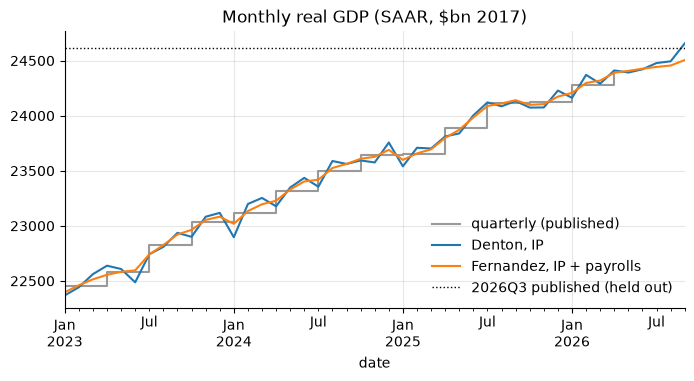

In [10]:
fig, ax = plt.subplots()
window = slice("2023-01", None)
Y[window].resample("MS").ffill().plot(
    ax=ax, color="0.6", drawstyle="steps-post", label="quarterly (published)"
)
gdp_m_denton[window].plot(ax=ax, label="Denton, IP")
gdp_m_fe[window].plot(ax=ax, label="Fernandez, IP + payrolls")
ax.axhline(target, color="k", ls=":", lw=1, label="2026Q3 published (held out)")
ax.set_title("Monthly real GDP (SAAR, $bn 2017)")
ax.legend()

**Choosing**: Denton when you trust the indicator's *profile* and only need
it benchmarked; Chow–Lin when target and indicators cointegrate (residual
stationary, $\hat\rho$ well inside the unit interval); Fernández or Litterman
when $\hat\rho$ runs to 1. R's `tempdisagg` package implements all of them and
is the reference to check against.

## Pitfalls

* Disaggregate **levels**, not growth rates, and choose sum vs mean to match
  the series (chapter 3).
* Interpolated or disaggregated values are estimates. Using them as data in
  a regression understates standard errors.
* Seasonally adjusted low-frequency data with an NSA indicator (or the other
  way round) produces spurious seasonal patterns in the result.

## Summary

* Short gaps in a smooth series: `interpolate(method="time")`.
* Gaps in a series that moves with others: a state-space model (Kalman
  smoother) or a regression on related series.
* Low → high frequency: never plain `interpolate`, it breaks the
  aggregation constraint. Use **Denton** (no or one indicator) or
  **Chow-Lin** (one or more indicators, estimated by GLS).

## Exercises

1. Remove two weeks of daily Brent (`DCOILBRENTEU`, 4–15 March 2024) and fill them with `ffill`, linear, time and `pchip` interpolation. Which method has the smallest error against the true prices, and which would you choose for a price series?
2. Repeat the Kalman-smoother gap experiment on log industrial production (`INDPRO`, 2010–2019) with gaps of 3, 8 and 12 months. How do the RMSE in the gap and the width of the 95% band change with the gap length, compared with linear interpolation?
3. Disaggregate real GDP (`GDPC1`) to monthly for 2019–2021 with Denton, once with a constant indicator and once with industrial production (`INDPRO`). Check that both average to the published quarters, and compare the monthly paths in March–May 2020: which is more plausible?
4. The chapter evaluates the nowcast on one held-out quarter. Repeat it for every quarter from 2012Q1 to 2019Q4 for Denton (IP) and Chow–Lin (IP and payrolls), and compute the RMSE of each against "no change". Does Denton's win in 2026Q3 survive?